In [2]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import auc

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet


from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay

from sklearn.neighbors import KNeighborsRegressor as KNNR

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;

from sklearn.ensemble import RandomForestClassifier as RFC;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from yellowbrick.model_selection import LearningCurve
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import LeavePOut;

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

from sklearn.datasets import fetch_openml

import warnings as yapping
yapping.simplefilter("ignore")

#1 (1 балл) Загрузите предложенный вам датасет с помощью функции `sklearn.datasets.fetch_openml`. Выведите текстовое описание загруженного датасета. Определите какая бизнес-задача ставится. Переведите бизнес-задачу в задачу машинного обучения.

In [4]:
#Загрузите предложенный вам датасет
dataset = fetch_openml('user-knowledge',as_frame=True)
y = dataset.target
x = dataset.frame[dataset.feature_names]

#Выведите текстовое описание загруженного датасета
print(dataset.DESCR)

#Определите какая бизнес-задача ставится.
#Ответ: предсказать уровень знаний студента по набору объективных параметров: времени обучения студента и его оценке за экзамен

#Переведите бизнес-задачу в задачу машинного обучения.
#Задача классификации с пятью уникальными классами по 6 атрибутам

**Author**:   
**Source**: UCI    
**Please cite**:  H. T. Kahraman, Sagiroglu, S., Colak, I., Developing intuitive knowledge classifier and modeling of users' domain dependent data in web, Knowledge Based Systems, vol. 37, pp. 283-295, 2013.   

* Title:  

User Knowledge Modeling Data Set 

* Abstract: 

It is the real dataset about the students' knowledge status about the subject of Electrical DC Machines. The dataset had been obtained from Ph.D. Thesis.

* Source:

-- Creators: Hamdi Tolga Kahraman (htolgakahraman '@' yahoo.com) 
-- Institution: Faculty of Technology, Department of Software Engineering, Karadeniz Technical University, Trabzon, Turkiye 
-- Creators: Ilhami Colak (icolak '@' gazi.edu.tr) 
-- Institution: Faculty of Technology, Department of Electrical and Electronics Engineering, Gazi University, Ankara, Turkiye 
-- Creators: Seref Sagiroglu (ss '@' gazi.edu.tr) 
-- Institution: Faculty of Technology, Department of Computer Engineering, Gazi University, Ankara, Turki

In [ ]:
y.unique()

['4', '1', '2', '3', '5']
Categories (5, object): ['1', '2', '3', '4', '5']

#2 (1 балл) Проведите предварительный анализ датасета. Выведите основную статистическую информацию о данных. Проверьте дисбаланс целевого признака.

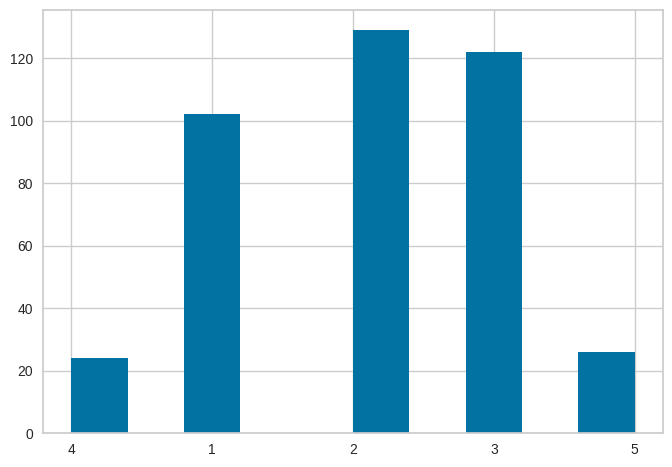

Class
2    129
3    122
1    102
5     26
4     24
Name: count, dtype: int64


In [ ]:
#Выведите основную статистическую информацию о данных.
dataset.frame.describe()

#Проверьте дисбаланс целевого признака
plt.hist(y); plt.show();
print(y.value_counts());
#дизбаланс присутствует, класс 4 и 5 встречается в несколько раз реже чем 1, 2 или 3

#3 (1 балл) Убедитесь, что данные пригодны для моделирования. В данных не должно быть пропущенных значений, все признаки должны быть численными. Если эти условия нарушаются, исправьте это.

In [ ]:
df = dataset.frame.dropna()
x = df[x.columns]
y = df[y.name]
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   V1      403 non-null    float64 
 1   V2      403 non-null    float64 
 2   V3      403 non-null    float64 
 3   V4      403 non-null    float64 
 4   V5      403 non-null    float64 
 5   Class   403 non-null    category
dtypes: category(1), float64(5)
memory usage: 16.5 KB
None


#4 (1 балл) Обучите любую линейную модель, которая решает поставленную задачу. Выведите с помощью метода `score()` результат метрики оценки модели. Опишите какая метрика подсчитывается в методе `score()`.

In [ ]:
#Обучите любую линейную модель
xtr, xts,  ytr, yts = train_test_split(x,y,train_size=0.8, random_state=4)
m = LR().fit(xtr,ytr)

#Выведите с помощью метода score() результат метрики оценки
print(m.score(xts,yts))

#какая метрика подсчитывается в методе score()
#Метод score считает значение R2, т.е.  1 - sum( [y_true-y_predicted]**2/Var(y) ) или же 1 - sum( [y_true-y_predicted]**2)/sum([y_pred - y_mean]**2 )

0.8271604938271605


#5 (1 балл) К поставленной задачи машинного обучения подберите еще 3 метрики. С помощью их оцените обученную линейную модель.

In [ ]:
#еще 3 метрики
true = yts
pred = m.predict(xts)
prob = m.predict_proba(xts)
#f1_macro (f1 = 2 * precision * recall / (precision + recall))
print(f"f1 macro: {f1(true,pred,average='macro')}")
#precision_macro = TP / (TP + FP)
print(f"precision macro: {precision_score(true,pred,average='macro')}")
#recall = TP / (TP + FN)
print(f"recall macro: {recall_score(true,pred,average='macro')}")

f1 macro: 0.5249038745933156
precision macro: 0.5285853658536586
recall macro: 0.5428571428571429


#6 (1 балл) Для задач классификации: Постройте для этой модели кривые ROC. Вычислите для этой модели метрики площади под кривыми ROC-AUC. Найдите оптимальное значения порога модели.

порог: 0.5158122768642902
геометрическое среднее: 0.9911892555667041
порог: 0.4037188117605182
геометрическое среднее: 0.8687444855261388
порог: 0.3325935743208567
геометрическое среднее: 0.9023778112773575
порог: 0.12549212993752556
геометрическое среднее: 0.9405399431259602
порог: 0.16620285103796062
геометрическое среднее: 1.0


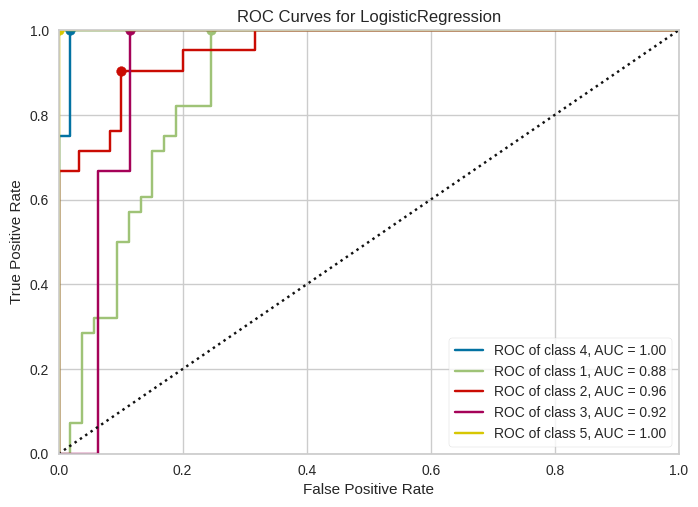

<Axes: title={'center': 'ROC Curves for LogisticRegression'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
#Постройте для этой модели кривые ROC
#метрики площади под кривыми ROC-AUC
visualizer = ROCAUC(LR(),classes=y.unique(),micro=False, macro=False, per_class=True)
visualizer.fit(xtr, ytr)
visualizer.score(xts, yts)
ax = visualizer.ax

#оптимальное значения порога модели
#будем использовать среднее геометрическое TPR и FPR для оптимизации порога:
for i in range(len(m.classes_)):
  cl = m.classes_[i]
  ys = (yts == cl).astype(int)
  probs = prob[:,i]

  fpr, tpr, threshholds = roc(ys,probs)
  gmean = np.sqrt(tpr * (1-fpr))
  print(f'порог: {threshholds[argmax(gmean)]}\nгеометрическое среднее: {gmean[argmax(gmean)]}')

  ind = argmax(gmean)
  ax.scatter(fpr[ind],tpr[ind])

visualizer.show()

#7 (1 балл) Для задач классификации: Постройте для этой модели кривые PR. Вычислите для этой модели метрики площади под кривыми PR-AUC. Найдите оптимальное значения порога модели.


PR кривая для класса 1:



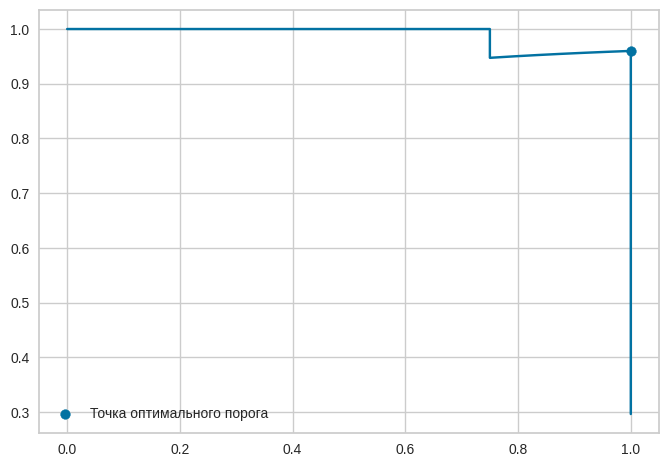

Площадь под PR: 0.9885610704131871

ROC кривая для класса 1:



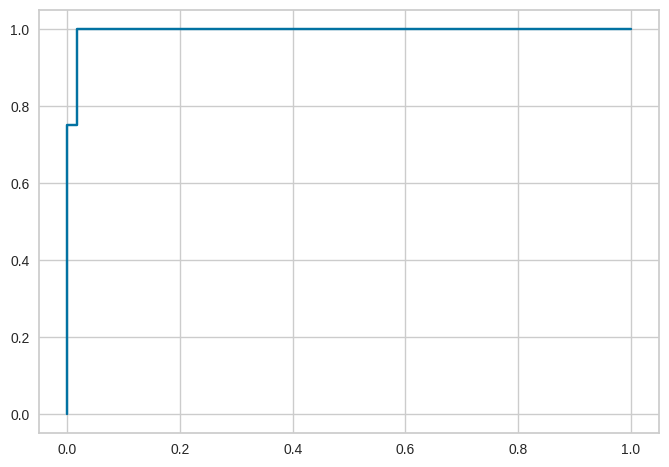

Площадь под ROC: 0.9956140350877193


PR кривая для класса 2:



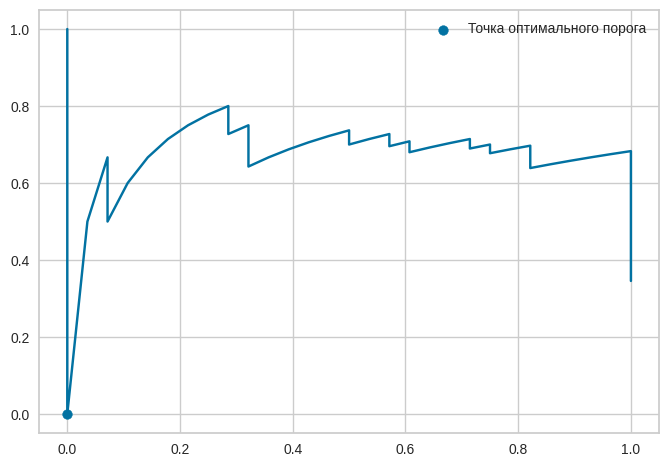

Площадь под PR: 0.6715903510584535

ROC кривая для класса 2:



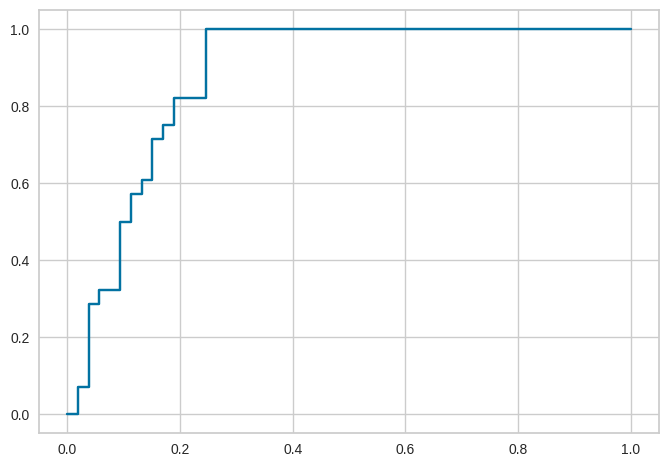

Площадь под ROC: 0.8793800539083558


PR кривая для класса 3:



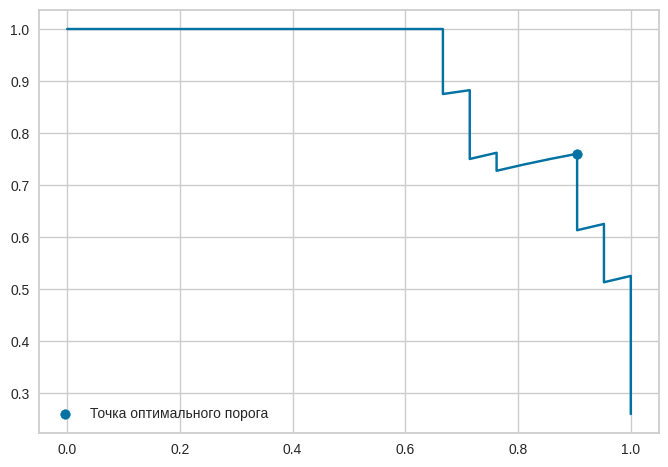

Площадь под PR: 0.9050122628225272

ROC кривая для класса 3:



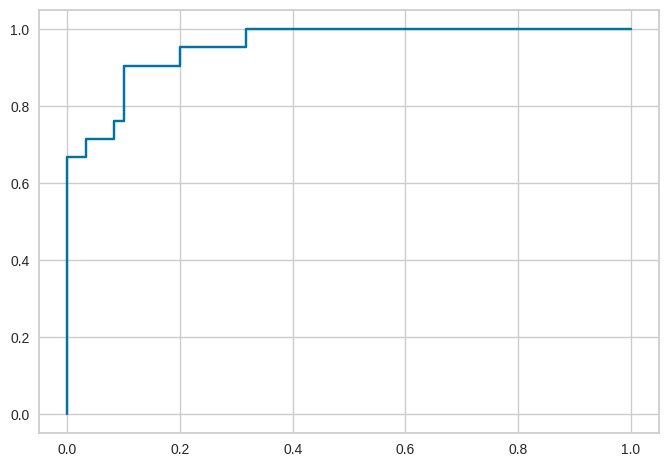

Площадь под ROC: 0.9555555555555555


PR кривая для класса 4:



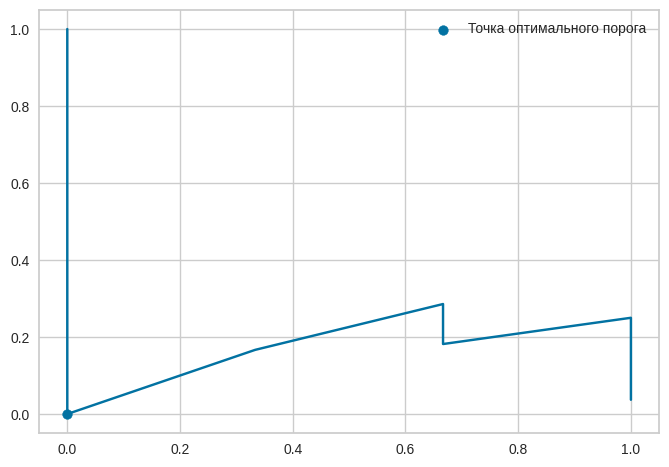

Площадь под PR: 0.17514430014430013

ROC кривая для класса 4:



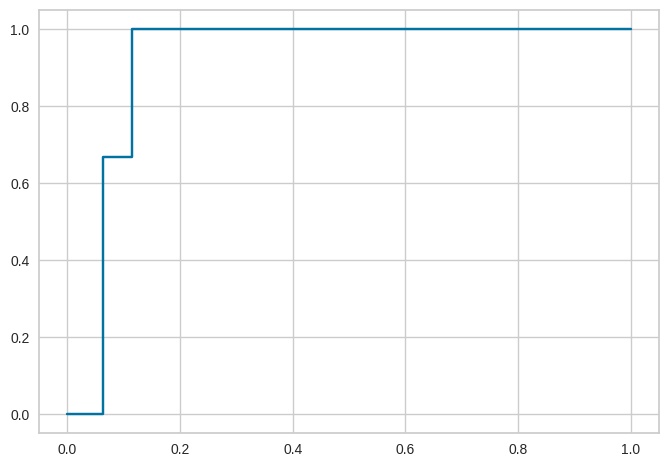

Площадь под ROC: 0.9188034188034188


PR кривая для класса 5:



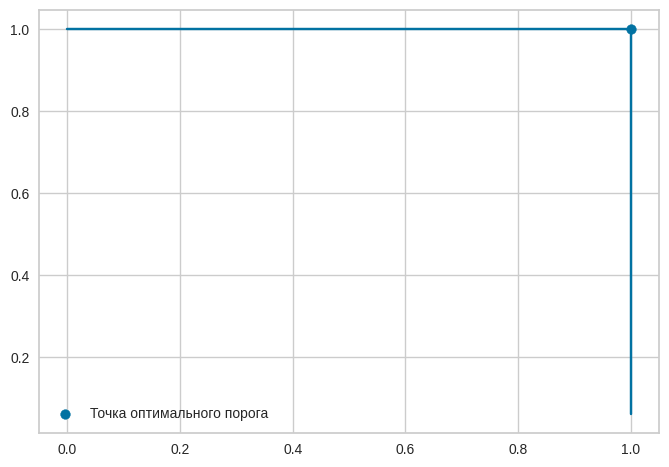

Площадь под PR: 1.0

ROC кривая для класса 5:



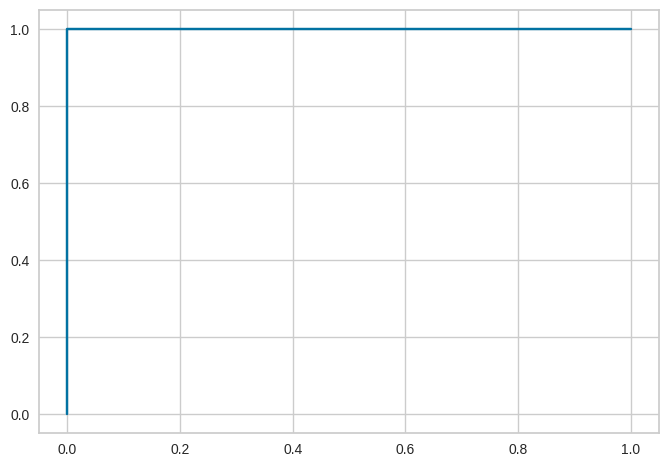

Площадь под ROC: 1.0



In [ ]:
for i in range(len(m.classes_)):
  cl = m.classes_[i]
  ys = (yts == cl).astype(int)
  probs = prob[:,i]
  #кривые PR
  print(f'\nPR кривая для класса {cl}:\n')
  precision, recall = prc(ys,probs)[:-1]
  plt.plot(recall,precision);

  #оптимальное значения порога модели
  #оптимальным будем считать значение с максимальной метрикой f1 для класса
  f = 2 * (precision*recall) / (precision + recall)
  ind = argmax(f)
  plt.scatter(recall[ind],precision[ind],label = 'Точка оптимального порога');plt.legend()
  plt.show()
  print(f'Площадь под PR: {auc(recall, precision)}')

  #метрики площади под кривыми PR-AUC
  print(f'\nROC кривая для класса {cl}:\n')
  fpr,tpr = roc(ys,probs)[:-1]
  plt.plot(fpr,tpr);plt.show()
  print(f'Площадь под ROC: {roc_auc_score(ys, probs)}')
  print()

#8 (1 балл) Обоснуйте выбор типа разбиения данных при кросс-валидации для вашей задачи машинного обучения. Обучите любую другую модель используя кросс-валидацию данных.

In [ ]:
print(f'____________________________________\n\nLinear regression classifier:\n')
cv = StratifiedKFold(n_splits = 10, random_state = 4, shuffle =True)
for i, (train_index, test_index) in enumerate(cv.split(x, y)):
    print(f"Fold {i}:")
    #print(f"  Train: index={train_index}")
    #print(f"  Test:  index={test_index}")
    trainx, trainy = x.iloc[train_index],y[train_index]
    testx,  testy =  x.iloc[test_index], y[test_index]
    m = LR()
    m.fit(trainx,trainy)
    print(f'Fold: {i}')
    print(f'Score: {m.score(testx,testy)}\n')

#Обоснуйте выбор типа разбиения
#Используется стратификация, потому что классов 4,5 в несколько раз меньше в датасете, чем классов 1,2,3

print(f'____________________________________\n\nRandom Forest classifier:\n')
#RFC
cv = StratifiedKFold(n_splits = 10, random_state = 4, shuffle =True)
for i, (train_index, test_index) in enumerate(cv.split(x, y)):
    print(f"Fold {i}:")
    #print(f"  Train: index={train_index}")
    #print(f"  Test:  index={test_index}")
    trainx, trainy = x.iloc[train_index],y[train_index]
    testx,  testy =  x.iloc[test_index], y[test_index]
    m = RFC()
    m.fit(trainx,trainy)
    print(f'Fold: {i}')
    print(f'Score: {m.score(testx,testy)}\n')

____________________________________

Linear regression classifier:

Fold 0:
Fold: 0
Score: 0.7560975609756098

Fold 1:
Fold: 1
Score: 0.7804878048780488

Fold 2:
Fold: 2
Score: 0.7804878048780488

Fold 3:
Fold: 3
Score: 0.75

Fold 4:
Fold: 4
Score: 0.825

Fold 5:
Fold: 5
Score: 0.8

Fold 6:
Fold: 6
Score: 0.85

Fold 7:
Fold: 7
Score: 0.8

Fold 8:
Fold: 8
Score: 0.825

Fold 9:
Fold: 9
Score: 0.8

____________________________________

Random Forest classifier:

Fold 0:
Fold: 0
Score: 0.8536585365853658

Fold 1:
Fold: 1
Score: 0.9024390243902439

Fold 2:
Fold: 2
Score: 0.926829268292683

Fold 3:
Fold: 3
Score: 0.85

Fold 4:
Fold: 4
Score: 0.975

Fold 5:
Fold: 5
Score: 0.925

Fold 6:
Fold: 6
Score: 0.875

Fold 7:
Fold: 7
Score: 0.875

Fold 8:
Fold: 8
Score: 0.95

Fold 9:
Fold: 9
Score: 0.9



#9 (2 балл) Проведите диагностику любой модели. Постройте кривые обучения. Сделайте вывод о переобученности или недообученности модели.


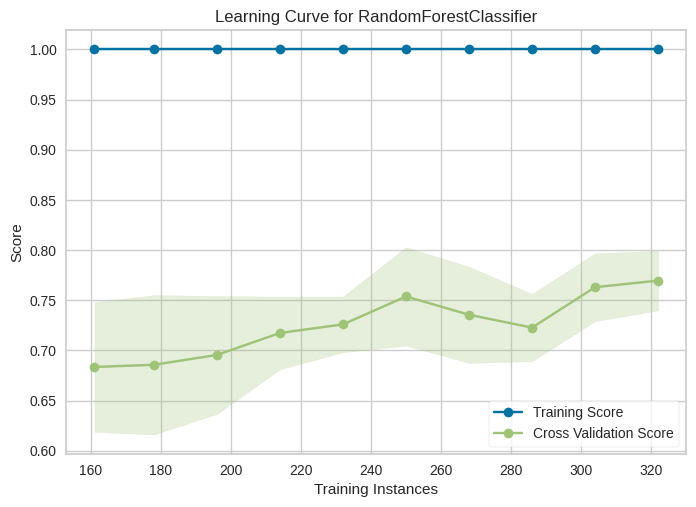

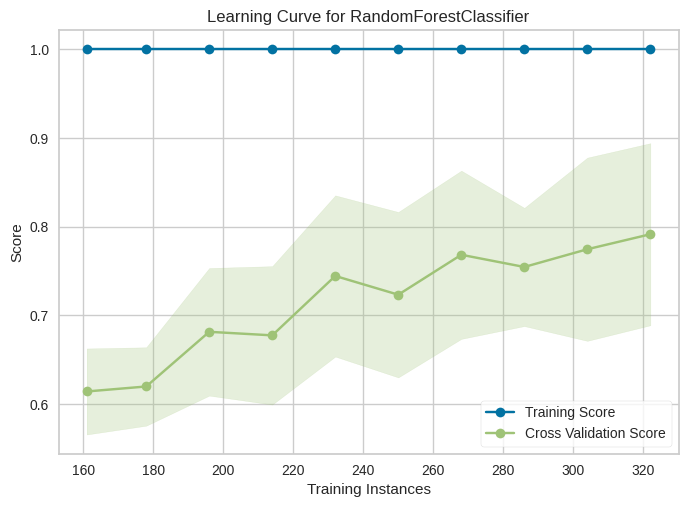

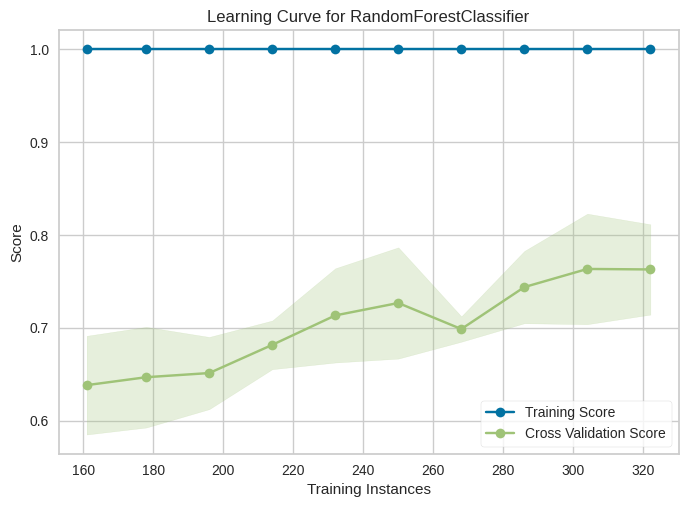

<Axes: title={'center': 'Learning Curve for RandomForestClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [10]:
LearningCurve(RFC(), scoring='recall_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()
LearningCurve(RFC(), scoring='precision_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()
LearningCurve(RFC(), scoring='f1_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()

#10 (2 балл) Исследуйте как любой из гиперпараметров модели влияет на эффективность модели.

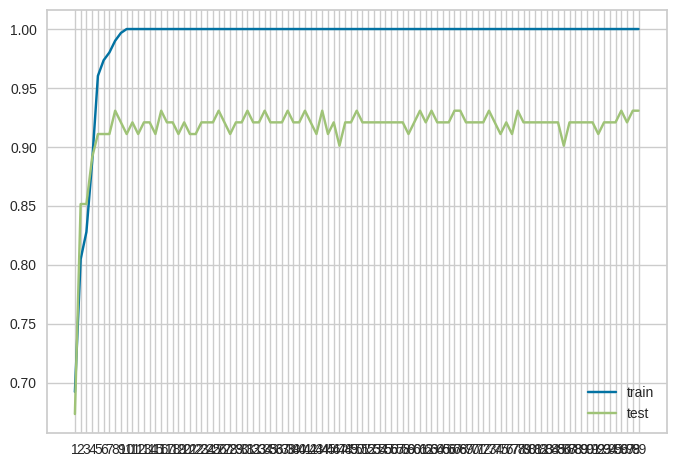

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=3)
xp = np.array(range(1,100))
ms = [RFC(max_depth = i).fit(x_train,y_train) for i in xp]
yp_train = [i.score(x_train,y_train) for i in ms]
yp_test = [i.score(x_test,y_test) for i in ms]
plt.xticks(xp)
plt.plot(xp,yp_train, label="train")
plt.plot(xp,yp_test, label="test")
plt.legend()
plt.show()

'''
Максимальная глубина случайного

'''
print()